# COMP 551 — MiniProject 2: Training and Evaluation Practices

**Group members:** _Mounir Ammam_, _Henry_, _John_

**Dataset:** UCI Spambase (binary classification: spam = 1, not spam = 0)

## 0. Setup

In [7]:
!pip install ucimlrepo

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)


## 1. Load the data

In [9]:
# load spambase.data
try:
    from ucimlrepo import fetch_ucirepo
    spambase = fetch_ucirepo(id=94)
    X = spambase.data.features.to_numpy(dtype=float)
    y = spambase.data.targets.to_numpy(dtype=float).ravel()
except Exception as e:
    print("ucimlrepo failed, reading local spambase.data:", e)
    df = pd.read_csv('spambase.data', header=None)
    X = df.iloc[:, :57].to_numpy(dtype=float)
    y = df.iloc[:, 57].to_numpy(dtype=float)

print("X shape:", X.shape, "| y shape:", y.shape)
print(f"Class balance: spam = {y.mean():.3f}, not spam = {1 - y.mean():.3f}")

X shape: (4601, 57) | y shape: (4601,)
Class balance: spam = 0.394, not spam = 0.606


## 2. Train / test split (5% train, 95% test)


In [10]:
N = X.shape[0]
perm = rng.permutation(N)
n_train = int(0.05 * N)

train_idx, test_idx = perm[:n_train], perm[n_train:]
X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

print(f"Train: {X_train.shape[0]} rows | spam fraction = {y_train.mean():.3f}")
print(f"Test:  {X_test.shape[0]} rows | spam fraction = {y_test.mean():.3f}")

Train: 230 rows | spam fraction = 0.387
Test:  4371 rows | spam fraction = 0.394


## 3. Preprocessing

In [11]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1.0

X_train_s = (X_train - mu) / sigma
X_test_s  = (X_test  - mu) / sigma

print("Train means (should be ~0):", np.round(X_train_s.mean(axis=0)[:5], 4))
print("Train stds  (should be ~1):", np.round(X_train_s.std(axis=0)[:5], 4))
print("Constant features in train set:", int((X_train.std(axis=0) == 0).sum()))

Train means (should be ~0): [-0. -0.  0. -0. -0.]
Train stds  (should be ~1): [1. 1. 1. 1. 1.]
Constant features in train set: 0


---
# Task 1: Logistic Regression with SGD

Convention used: $\mathcal{L}_{reg}(w,b) = \mathcal{L}(w,b) + \lambda \lVert w \rVert_2^2$, so the regularization gradient is $2\lambda w$. The bias $b$ is not penalized. $\mathcal{L}$ is the **mean** binary cross-entropy over the batch.

### 1.1 Sigmoid

In [12]:
def sigmoid(z):
    """Numerically stable sigmoid: never calls exp on a large positive number."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

print(sigmoid(np.array([-1000.0, 0.0, 1000.0])))

[0.  0.5 1. ]


### 1.2 Loss and accuracy


In [13]:
def compute_loss(X, y, w, b, eps=1e-12):
    """Mean binary cross-entropy (no lambda term)."""
    p = np.clip(sigmoid(X @ w + b), eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

In [14]:
def compute_accuracy(X, y, w, b):
    """Fraction of correct predictions with threshold 0.5."""
    preds = (sigmoid(X @ w + b) >= 0.5).astype(float)
    return np.mean(preds == y)

### 1.3 Mini-batch SGD training


In [18]:
def compute_gradients(X, y, w, b, lam):
    """Gradient of mean BCE + lam*||w||^2. Bias is not regularized."""
    n = X.shape[0]
    err = sigmoid(X @ w + b) - y
    grad_w = X.T @ err / n + 2 * lam * w
    grad_b = np.mean(err)
    return grad_w, grad_b


def train(X, y, batch_size, lr, epochs, lam,
          rng=None, init_scale=0.0, shuffle=True, verbose=False):
    """
    Mini-batch SGD for L2-regularized logistic regression.
    Returns w, b, history (dict with per-epoch full-train loss and accuracy).
    """
    if rng is None:
        rng = np.random.default_rng(RANDOM_SEED)

    n, d = X.shape
    w = rng.normal(0, init_scale, size=d) if init_scale > 0 else np.zeros(d)
    b = 0.0
    history = {'loss': [], 'acc': []}

    for epoch in range(epochs):
        idx = rng.permutation(n) if shuffle else np.arange(n)
        for start in range(0, n, batch_size):
            batch = idx[start:start + batch_size]
            grad_w, grad_b = compute_gradients(X[batch], y[batch], w, b, lam)
            w -= lr * grad_w
            b -= lr * grad_b

        history['loss'].append(compute_loss(X, y, w, b))
        history['acc'].append(compute_accuracy(X, y, w, b))

        if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch:3d} | loss {history['loss'][-1]:.4f} | acc {history['acc'][-1]:.4f}")

    return w, b, history

### 1.4 Sanity checks

In [10]:
# loss shuold decrease

w_tmp, b_tmp, h_tmp = train(X_train_s, y_train, batch_size=16, lr=0.1, epochs=5, lam=0)
print("Losses over 5 epochs:", np.round(h_tmp['loss'], 4))
assert h_tmp['loss'][-1] < h_tmp['loss'][0], "Loss did not decrease!"

# Shapes and lam = 0
assert w_tmp.shape == (X_train_s.shape[1],), f"Unexpected w shape {w_tmp.shape}"
print("w shape OK:", w_tmp.shape)

# Gradient check against finite differences (with lam > 0)
chk_rng = np.random.default_rng(0)
w_chk, b_chk, lam_chk = 0.01 * chk_rng.normal(size=X_train_s.shape[1]), 0.3, 1e-2
J = lambda w_, b_: compute_loss(X_train_s, y_train, w_, b_) + lam_chk * (w_ @ w_)

gw, gb = compute_gradients(X_train_s, y_train, w_chk, b_chk, lam_chk)
eps = 1e-6
num_gw = np.array([(J(w_chk + eps * e, b_chk) - J(w_chk - eps * e, b_chk)) / (2 * eps)
                   for e in np.eye(len(w_chk))])
num_gb = (J(w_chk, b_chk + eps) - J(w_chk, b_chk - eps)) / (2 * eps)
print(f"Max |grad_w - numerical| = {np.max(np.abs(gw - num_gw)):.2e}")
print(f"|grad_b - numerical|     = {abs(gb - num_gb):.2e}")

Losses over 5 epochs: [0.3616 0.2905 0.2545 0.231  0.2144]
w shape OK: (57,)
Max |grad_w - numerical| = 1.52e-10
|grad_b - numerical|     = 2.88e-11


### 1.5 Experiments (B = 16, η = 0.1, 200 epochs)

In [11]:
B, LR, EPOCHS = 16, 0.1, 200

w_noreg, b_noreg, hist_noreg = train(X_train_s, y_train, B, LR, EPOCHS, lam=0.0,
                                     rng=np.random.default_rng(RANDOM_SEED), verbose=True)
print(f"Final train loss = {hist_noreg['loss'][-1]:.4f} | train acc = {hist_noreg['acc'][-1]:.4f}")
print(f"||w|| = {np.linalg.norm(w_noreg):.3f}")

epoch   0 | loss 0.3616 | acc 0.9348
epoch  20 | loss 0.1291 | acc 0.9696
epoch  40 | loss 0.1010 | acc 0.9783
epoch  60 | loss 0.0869 | acc 0.9783
epoch  80 | loss 0.0777 | acc 0.9783
epoch 100 | loss 0.0711 | acc 0.9783
epoch 120 | loss 0.0659 | acc 0.9783
epoch 140 | loss 0.0617 | acc 0.9783
epoch 160 | loss 0.0582 | acc 0.9783
epoch 180 | loss 0.0552 | acc 0.9826
epoch 199 | loss 0.0527 | acc 0.9826
Final train loss = 0.0527 | train acc = 0.9826
||w|| = 6.712


In [12]:
LAM = 1e-2
w_l2, b_l2, hist_l2 = train(X_train_s, y_train, B, LR, EPOCHS, lam=LAM,
                            rng=np.random.default_rng(RANDOM_SEED), verbose=True)
print(f"Final train loss = {hist_l2['loss'][-1]:.4f} | train acc = {hist_l2['acc'][-1]:.4f}")
print(f"||w|| = {np.linalg.norm(w_l2):.3f}")

epoch   0 | loss 0.3638 | acc 0.9348
epoch  20 | loss 0.1573 | acc 0.9522
epoch  40 | loss 0.1454 | acc 0.9609
epoch  60 | loss 0.1428 | acc 0.9652
epoch  80 | loss 0.1414 | acc 0.9652
epoch 100 | loss 0.1413 | acc 0.9652
epoch 120 | loss 0.1411 | acc 0.9652
epoch 140 | loss 0.1410 | acc 0.9652
epoch 160 | loss 0.1413 | acc 0.9609
epoch 180 | loss 0.1411 | acc 0.9609
epoch 199 | loss 0.1411 | acc 0.9652
Final train loss = 0.1411 | train acc = 0.9652
||w|| = 2.472


In [13]:
# batch size 1 for the SGD vs mini-batch comparison
w_sgd, b_sgd, hist_sgd = train(X_train_s, y_train, batch_size=1, lr=LR, epochs=EPOCHS, lam=0.0,
                               rng=np.random.default_rng(RANDOM_SEED), verbose=True)
print(f"Final train loss = {hist_sgd['loss'][-1]:.4f} | train acc = {hist_sgd['acc'][-1]:.4f}")
print(f"||w|| = {np.linalg.norm(w_sgd):.3f}")

epoch   0 | loss 0.1787 | acc 0.9130
epoch  20 | loss 0.0387 | acc 0.9913
epoch  40 | loss 0.0274 | acc 0.9957
epoch  60 | loss 0.0220 | acc 0.9957
epoch  80 | loss 0.0186 | acc 0.9957
epoch 100 | loss 0.0163 | acc 1.0000
epoch 120 | loss 0.0145 | acc 0.9957
epoch 140 | loss 0.0131 | acc 0.9957
epoch 160 | loss 0.0120 | acc 1.0000
epoch 180 | loss 0.0110 | acc 1.0000
epoch 199 | loss 0.0103 | acc 1.0000
Final train loss = 0.0103 | train acc = 1.0000
||w|| = 18.123


### 1.6 Training curves

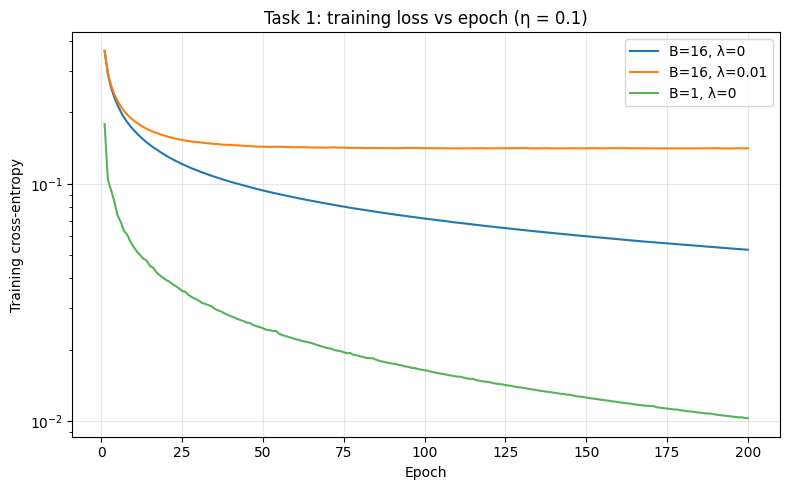

In [14]:
# training cross-entropy vs epoch for all runs

epochs_axis = np.arange(1, EPOCHS + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, hist_noreg['loss'], label='B=16, λ=0')
plt.plot(epochs_axis, hist_l2['loss'],    label=f'B=16, λ={LAM}')
plt.plot(epochs_axis, hist_sgd['loss'],   label='B=1, λ=0', alpha=0.8)
plt.xlabel('Epoch')
plt.ylabel('Training cross-entropy')
plt.title('Task 1: training loss vs epoch (η = 0.1)')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

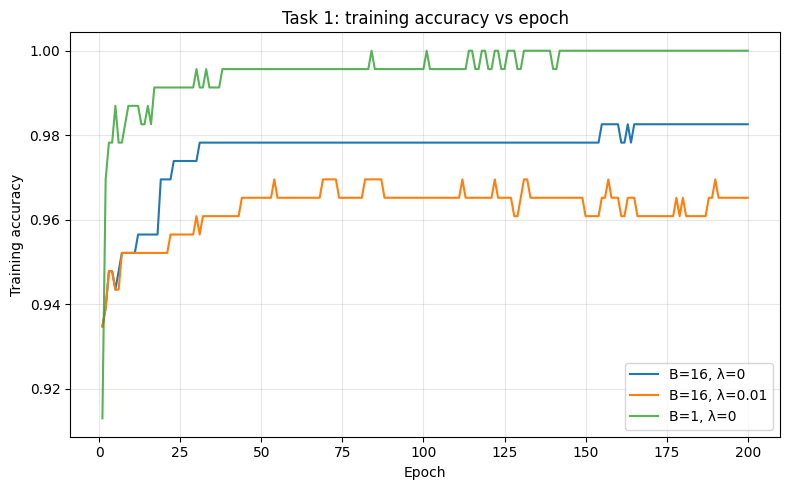

In [15]:
# training accuracy vs epoch curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, hist_noreg['acc'], label='B=16, λ=0')
plt.plot(epochs_axis, hist_l2['acc'],    label=f'B=16, λ={LAM}')
plt.plot(epochs_axis, hist_sgd['acc'],   label='B=1, λ=0', alpha=0.8)
plt.xlabel('Epoch')
plt.ylabel('Training accuracy')
plt.title('Task 1: training accuracy vs epoch')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 1.7 Notes for the report

- **Preprocessing:** One seeded (2026) 5%/95% split, giving 230 train and 4371 test rows. Features are z-scored with training-set mean/std only (std = 0 → 1), and the test set uses the same training statistics, so there is no leakage.
- **Stability:** Loss decreases smoothly for all run, fast in the first ~25 epochs, then slowly. Once the L2 run plateaus, it shows small fluctuations (loss 0.1410 → 0.1413, accuracy 0.9652 → 0.9609) from mini-batch noise around the optimum. Training accuracy moves in steps of 1/230 ≈ 0.4%, since one example flips at a time. Gradient check vs. finite differences: max error 1.5e-10.
- **No regularization vs L2:** With λ = 0, training loss keeps falling (0.053 at epoch 200) and ‖w‖ grows to 6.71, so the weights keep growing to fit the 230 training points ever more closely. With λ = 0.01, loss plateaus at 0.141 by epoch ~80 and ‖w‖ stays at 2.47, because the penalty stops the weights from growing. The cost is a slightly worse fit to the training set (96.5% vs 98.3% train accuracy).
- **SGD (B = 1) vs mini-batch (B = 16):** B = 1 makes 230 updates per epoch vs 15 for B = 16 (~15× more), so it reaches 100% train accuracy and a train CE of 0.010 with ‖w‖ = 18.1. Its per-epoch curve is still smooth because the loss is measured on the full training set after each epoch, but each epoch is slower because updates aren't vectorized.

---
# Task 2: Hyperparameter Tuning with K-Fold Cross-Validation

---
# Task 3: Bias–Variance Trade-off via λ Sweep (with K-Fold CV)


### Setup

In [19]:
import numpy as np
import matplotlib.pyplot as plt

seed = 2026


### 3.1 Hyperparameters

In [20]:
lr = 0.1
batch_size = 16
epochs = 200

n_folds = 5

### 3.2 Define Lambda Grid

In [21]:
lambdas = [0] + np.logspace(-6, 0, 20).tolist()

In [22]:
# Check
print("X_train shape:", X_train.shape)
print("y_train:", y_train.shape)

X_train shape: (230, 57)
y_train: (230,)


### 3.3 K-Fold Sweep

In [23]:
order = np.random.default_rng(seed).permutation(n_train)
folds = np.array_split(order, n_folds)

results = []

for lm in lambdas:

    loss_training = []
    loss_validation = []
    accuracy_training = []
    accuracy_validation = []

    for l in range(n_folds):

        # split the data into n sets
        validation_idx = folds[l]
        training_idx = np.concatenate([folds[m] for m in range(n_folds) if m != l])
        X_training = X_train[training_idx]
        y_training = y_train[training_idx]
        X_validation = X_train[validation_idx]
        y_validation = y_train[validation_idx]

        # standardize the features
        mean = X_training.mean(axis=0)
        sd = X_training.std(axis=0)
        sd[sd == 0] = 1
        X_training = (X_training - mean) / sd
        X_validation = (X_validation - mean) / sd

        # train the model
        w, b, _ = train(X_training, y_training, batch_size, lr, epochs, lm)

        # benchmarking the model
        loss_training.append(compute_loss(X_training, y_training, w, b))
        loss_validation.append(compute_loss(X_validation, y_validation, w, b))
        accuracy_training.append(compute_accuracy(X_training, y_training, w, b))
        accuracy_validation.append(compute_accuracy(X_validation, y_validation, w, b))

    # store the n-fold mean scores
    results.append(
        [
            lm,
            np.mean(loss_training),
            np.mean(loss_validation),
            np.mean(accuracy_training),
            np.mean(accuracy_validation),
        ]
    )

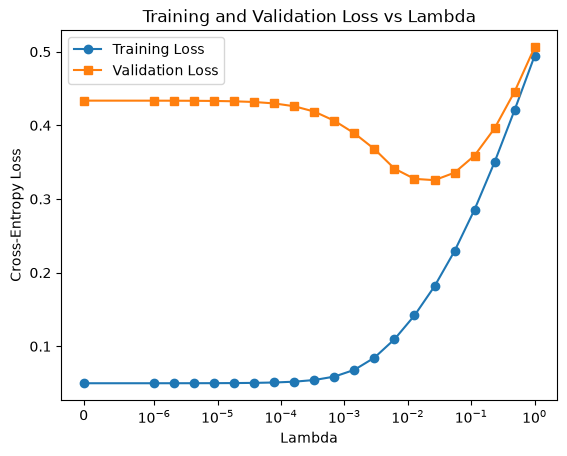

In [27]:
plt.plot([r[0] for r in results], [r[1] for r in results], label='Training Loss', marker='o')
plt.plot([r[0] for r in results], [r[2] for r in results], label='Validation Loss', marker='s')
plt.xscale('symlog', linthresh=1e-6)
plt.xlabel('Lambda')
plt.ylabel('Cross-Entropy Loss')
plt.title('Training and Validation Loss vs Lambda')
plt.legend()
plt.show()

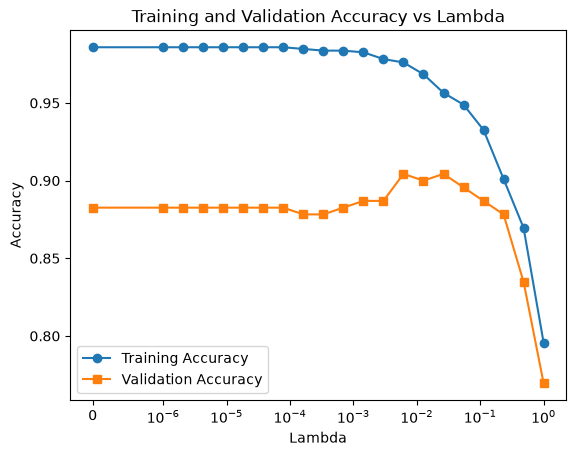

In [28]:
plt.plot([r[0] for r in results], [r[3] for r in results], label='Training Accuracy', marker='o')
plt.plot([r[0] for r in results], [r[4] for r in results], label='Validation Accuracy', marker='s')
plt.xscale('symlog', linthresh=1e-6)
plt.xlabel('Lambda')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy vs Lambda')
plt.legend()
plt.show()

### 3.4 Notes on Training and Validation Curves

1. As we can see from the loss and accuracy plots, a small lambda makes the model perform better on the training set, but worse on the validation set. This is because the model is overfitting the training data when regularization is small.
2. When we increase lambda, we increase the model's bias and reduce the model's expressive capacity, which eventually leads to underfitting. This is the right extreme of the graphs where the model performs poorly on both the training and the validation sets
3. 